Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


periode   n    auc  laju_gagal
2024-01 900 0.7881      0.0911
2024-02 900 0.7183      0.0789
2024-03 900 0.7440      0.0778
2024-04 900 0.7744      0.0789
2024-05 900 0.8122      0.0733
2024-06 900 0.7681      0.1056
2024-07 900 0.7798      0.1100
2024-08 900 0.7560      0.1122
2024-09 900 0.7726      0.1244
2024-10 900 0.7902      0.0978
2024-11 900 0.7525      0.1044
2024-12 900 0.7923      0.1222


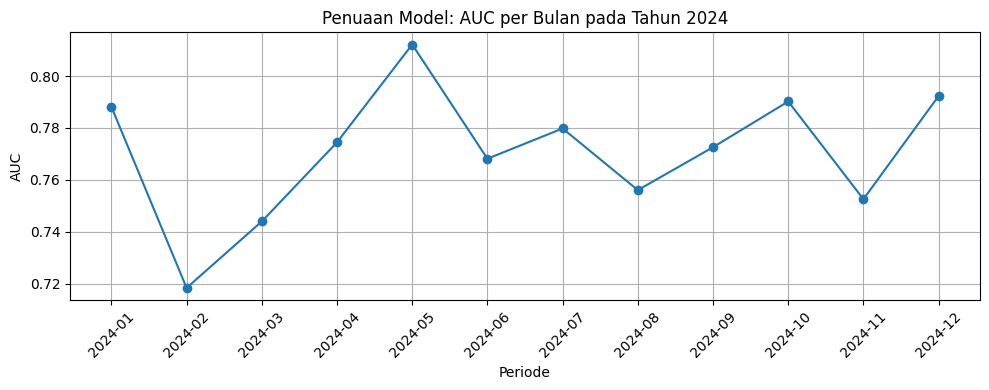

In [2]:
%pip install matplotlib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

df = pd.read_csv("../data/raw/kredit_sumatera.csv")
df["rasio_angsuran"] = df.angsuran_bulanan / df.penghasilan_bulanan
num = [
    "usia", "tanggungan", "lama_usaha_tahun", "penghasilan_bulanan",
    "ragam_penghasilan", "plafon_diajukan", "tenor_bulan", "bunga_tahunan",
    "rasio_angsuran", "rata_saldo_90h", "jumlah_tunggakan_12b"
]
X = df[num].join(pd.get_dummies(df[["segmen", "wilayah", "kanal"]]))
y = df.gagal_bayar

latih = df.periode <= "2023-12"
model = HistGradientBoostingClassifier(
    max_depth=6, learning_rate=0.06, max_iter=250, random_state=42
).fit(X[latih], y[latih])

baris = []
for periode in sorted(df.loc[df.periode > "2023-12", "periode"].unique()):
    m = df.periode == periode
    baris.append({
        "periode": periode,
        "n": int(m.sum()),
        "auc": roc_auc_score(y[m], model.predict_proba(X[m])[:, 1]),
        "laju_gagal": float(y[m].mean())
    })
hasil = pd.DataFrame(baris)
print(hasil.round(4).to_string(index=False))

# Grafik penurunan kinerja (titik periksa)
plt.figure(figsize=(10, 4))
plt.plot(hasil["periode"], hasil["auc"], marker="o")
plt.title("Penuaan Model: AUC per Bulan pada Tahun 2024")
plt.xlabel("Periode")
plt.ylabel("AUC")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [3]:
# (a) Apakah komposisi populasi bergeser?
awal = df[df.periode <= "2022-06"]
akhir = df[df.periode >= "2024-07"]
print("Perbandingan Proporsi Segmen (Awal vs Akhir):")
print(pd.DataFrame({
    "awal": awal.segmen.value_counts(normalize=True),
    "akhir": akhir.segmen.value_counts(normalize=True)
}).round(3))

# (b) Kinerja per segmen pada periode uji (> 2024-06)
print("\nAUC per Segmen pada Periode Uji:")
uji = df.periode > "2024-06"
skor = model.predict_proba(X[uji])[:, 1]
for seg, g in df[uji].groupby("segmen"):
    idx = g.index
    s = pd.Series(skor, index=df[uji].index)
    print(f"{seg:<18} n={len(g):5d} auc={roc_auc_score(y.loc[idx], s.loc[idx]):.3f}")

Perbandingan Proporsi Segmen (Awal vs Akhir):
                   awal  akhir
segmen                        
pegawai_tetap     0.414  0.311
wiraswasta        0.251  0.232
pedagang_musiman  0.141  0.179
petani            0.129  0.167
nelayan           0.066  0.111

AUC per Segmen pada Periode Uji:
nelayan            n=  597 auc=0.794
pedagang_musiman   n=  965 auc=0.766
pegawai_tetap      n= 1680 auc=0.784
petani             n=  904 auc=0.705
wiraswasta         n= 1254 auc=0.773
